In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import traceback

In [2]:
# h5파일 key 확인
def explore_h5(f, prefix=''):
    for key in f.keys():
        obj = f[key]
        fullname = prefix + '/' + key
        print(f'{fullname}')
        if isinstance(obj, h5py.Dataset):
            print(f'  type  : Dataset')
            print(f'  shape : {obj.shape}')
            print(f'  dtype : {obj.dtype}')
        else:
            print(f'  type  : Group')
        if obj.attrs:
            for k, v in obj.attrs.items():
                print(f'  attr  : {k} = {v}')
        if isinstance(obj, h5py.Group):
            explore_h5(obj, fullname)

h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_registration'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

for subject in files:
    print('='*80)
    print(subject)
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        explore_h5(f)

Subject1_motion_940_uv.h5
/bvp_data
  type  : Dataset
  shape : (1965,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (1965, 64, 64)
  dtype : float32
  attr  : fps = 30
/valid_mask
  type  : Dataset
  shape : (1965,)
  dtype : bool
  attr  : fail_rate = 0.0
Subject1_still_940_uv.h5
/bvp_data
  type  : Dataset
  shape : (5378,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (5378, 64, 64)
  dtype : float32
  attr  : fps = 30
/valid_mask
  type  : Dataset
  shape : (5378,)
  dtype : bool
  attr  : fail_rate = 0.0
Subject2_motion_940_uv.h5
/bvp_data
  type  : Dataset
  shape : (1821,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (1821, 64, 64)
  dtype : float32
  attr  : fps = 30
/valid_mask
  type  : Dataset
  shape : (1821,)
  dtype : bool
  attr  : fail_rate = 0.0
Subject2_still_940_uv.h5
/bvp_data
  type  : Dataset
  shape : (6300,)
  dtype : float64
/nir_uv_data
  type  : Dataset
  shape : (6300, 64, 64)
  dtype : float32
  attr  : fps = 30
/va

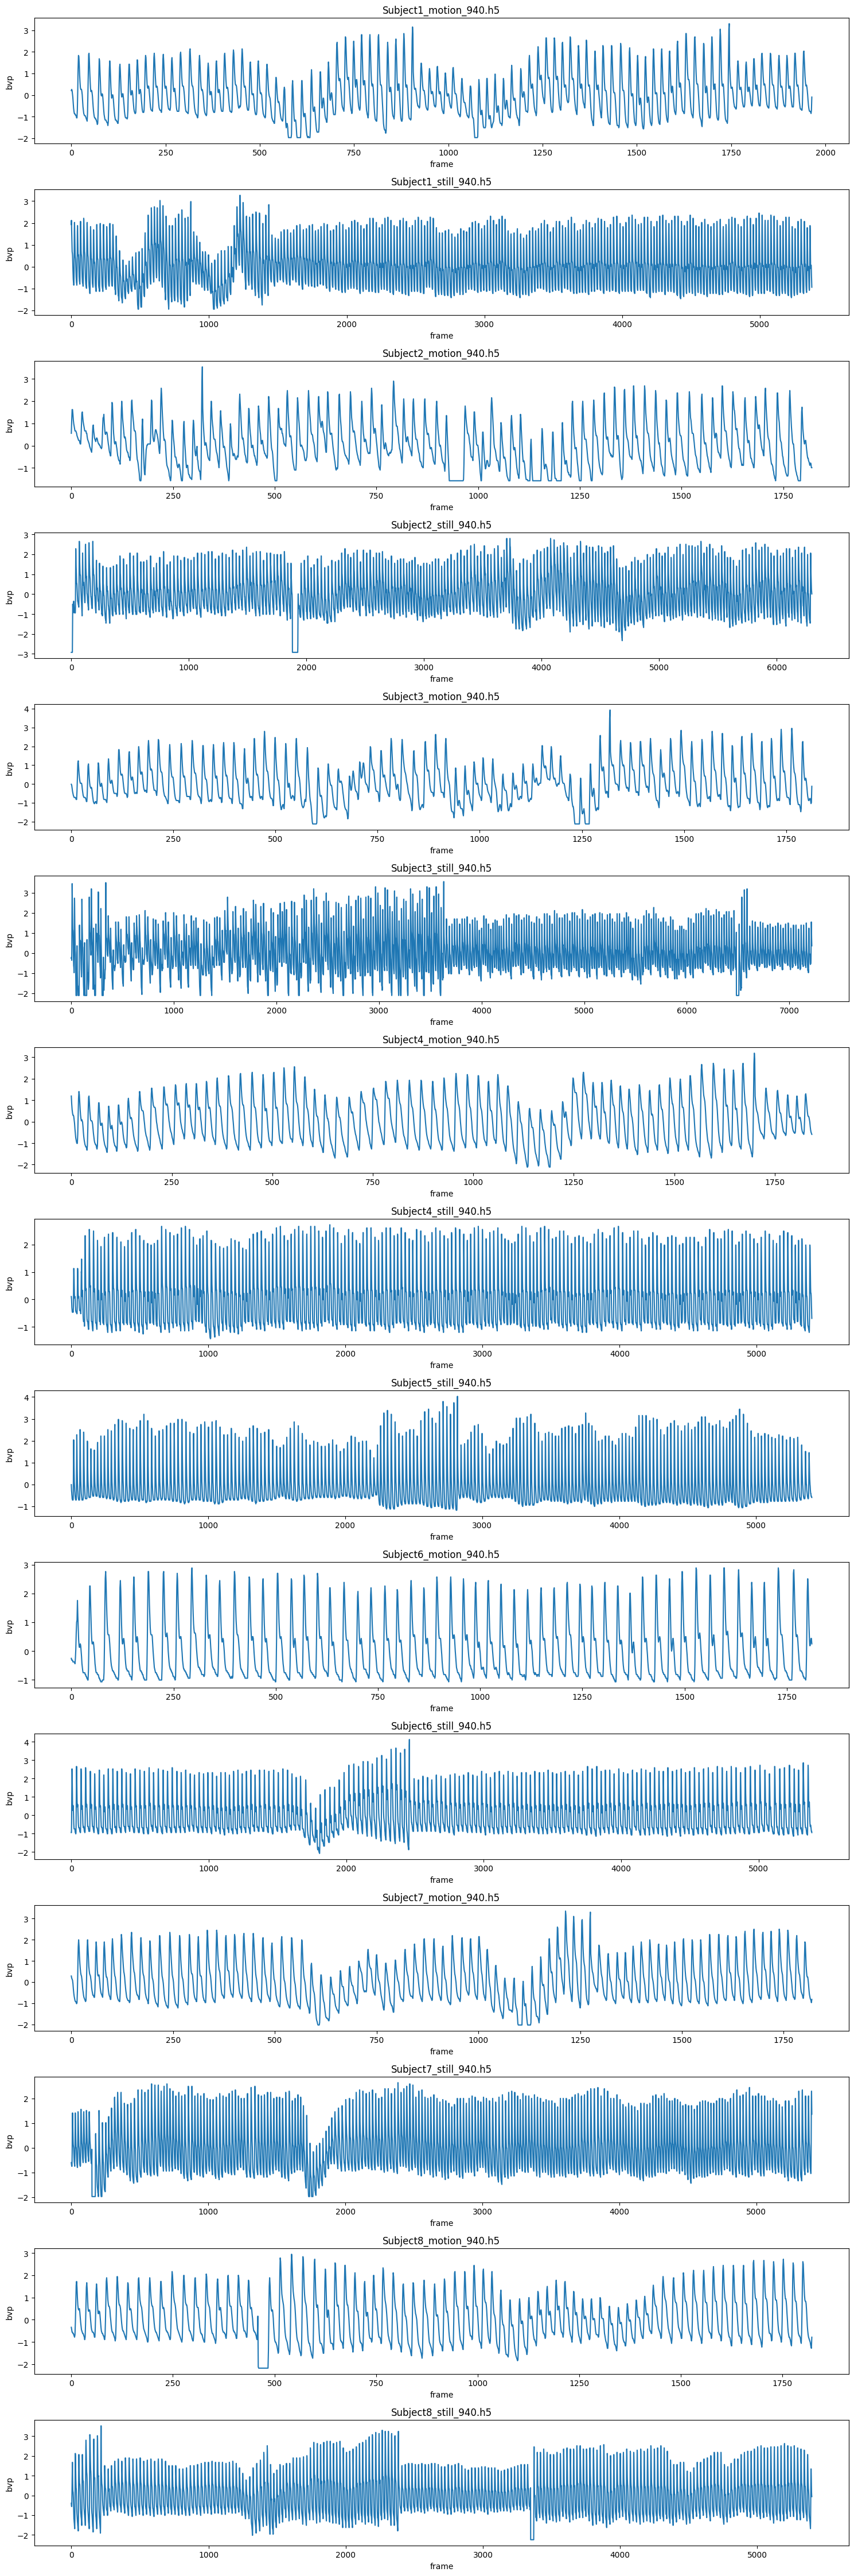

저장완료: bvp_all_subjects.png


In [6]:
# gt ppg 파형확인
import h5py
import os
import matplotlib.pyplot as plt

h5_dir = "/nasdata4/2yhy/rPPG_code/rPPG_datasets/h5_data/MR-NIRP_indoor"
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

fig, axes = plt.subplots(len(files), 1, figsize=(15, 3*len(files)))

for i, subject in enumerate(files):
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        bvp = f['bvp_data'][:]
    
    axes[i].plot(bvp)
    axes[i].set_title(subject)
    axes[i].set_xlabel('frame')
    axes[i].set_ylabel('bvp')

plt.tight_layout()
plt.show()
print("저장완료: bvp_all_subjects.png")

Subject1_still_940.h5
(5378, 128, 128, 1)
uint8


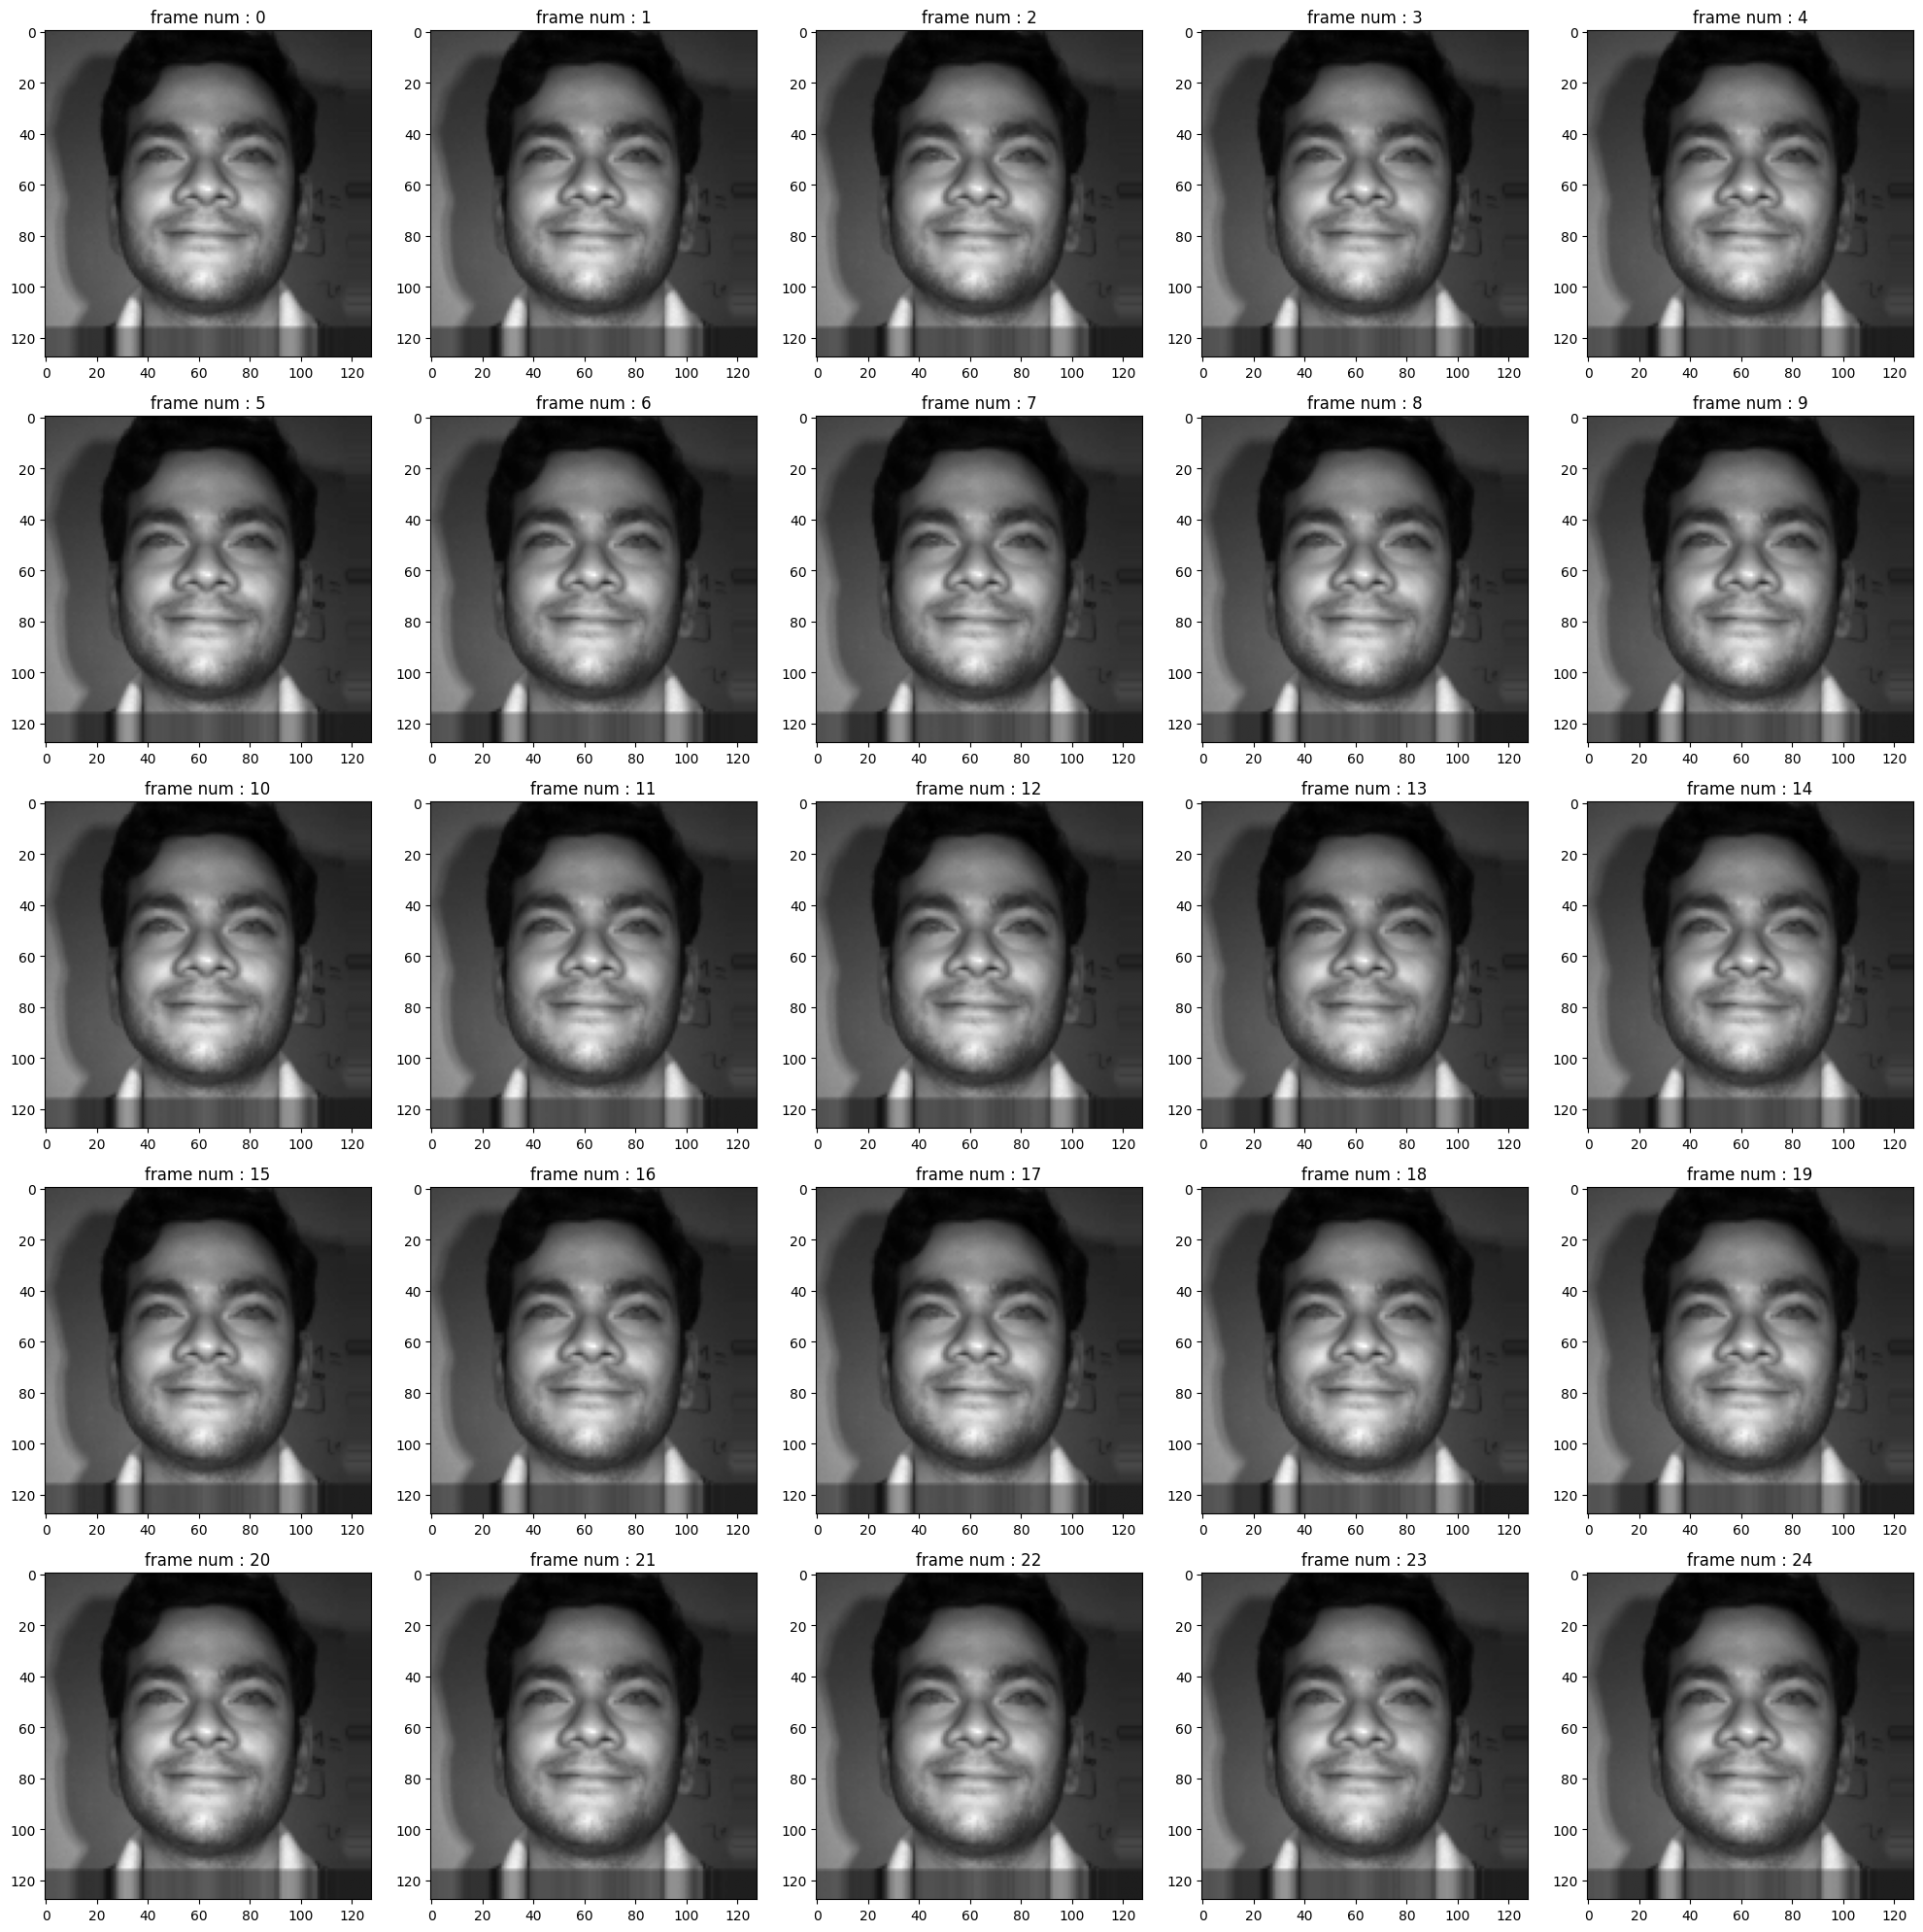

In [4]:
id = 1

h5_dir = "/nasdata4/2yhy/rPPG_code/rPPG_datasets/h5_data/MR-NIRP_indoor"
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])
print(files[id])

with h5py.File(os.path.join(h5_dir, files[id]), 'r') as f:
    video = f['imgs'][:]

print(video.shape)
print(video.dtype)
#비디오 사진 확인
fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :
    im = im.squeeze(-1)
    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

Subject1_still_940_uv.h5
(5378, 64, 64)
float32


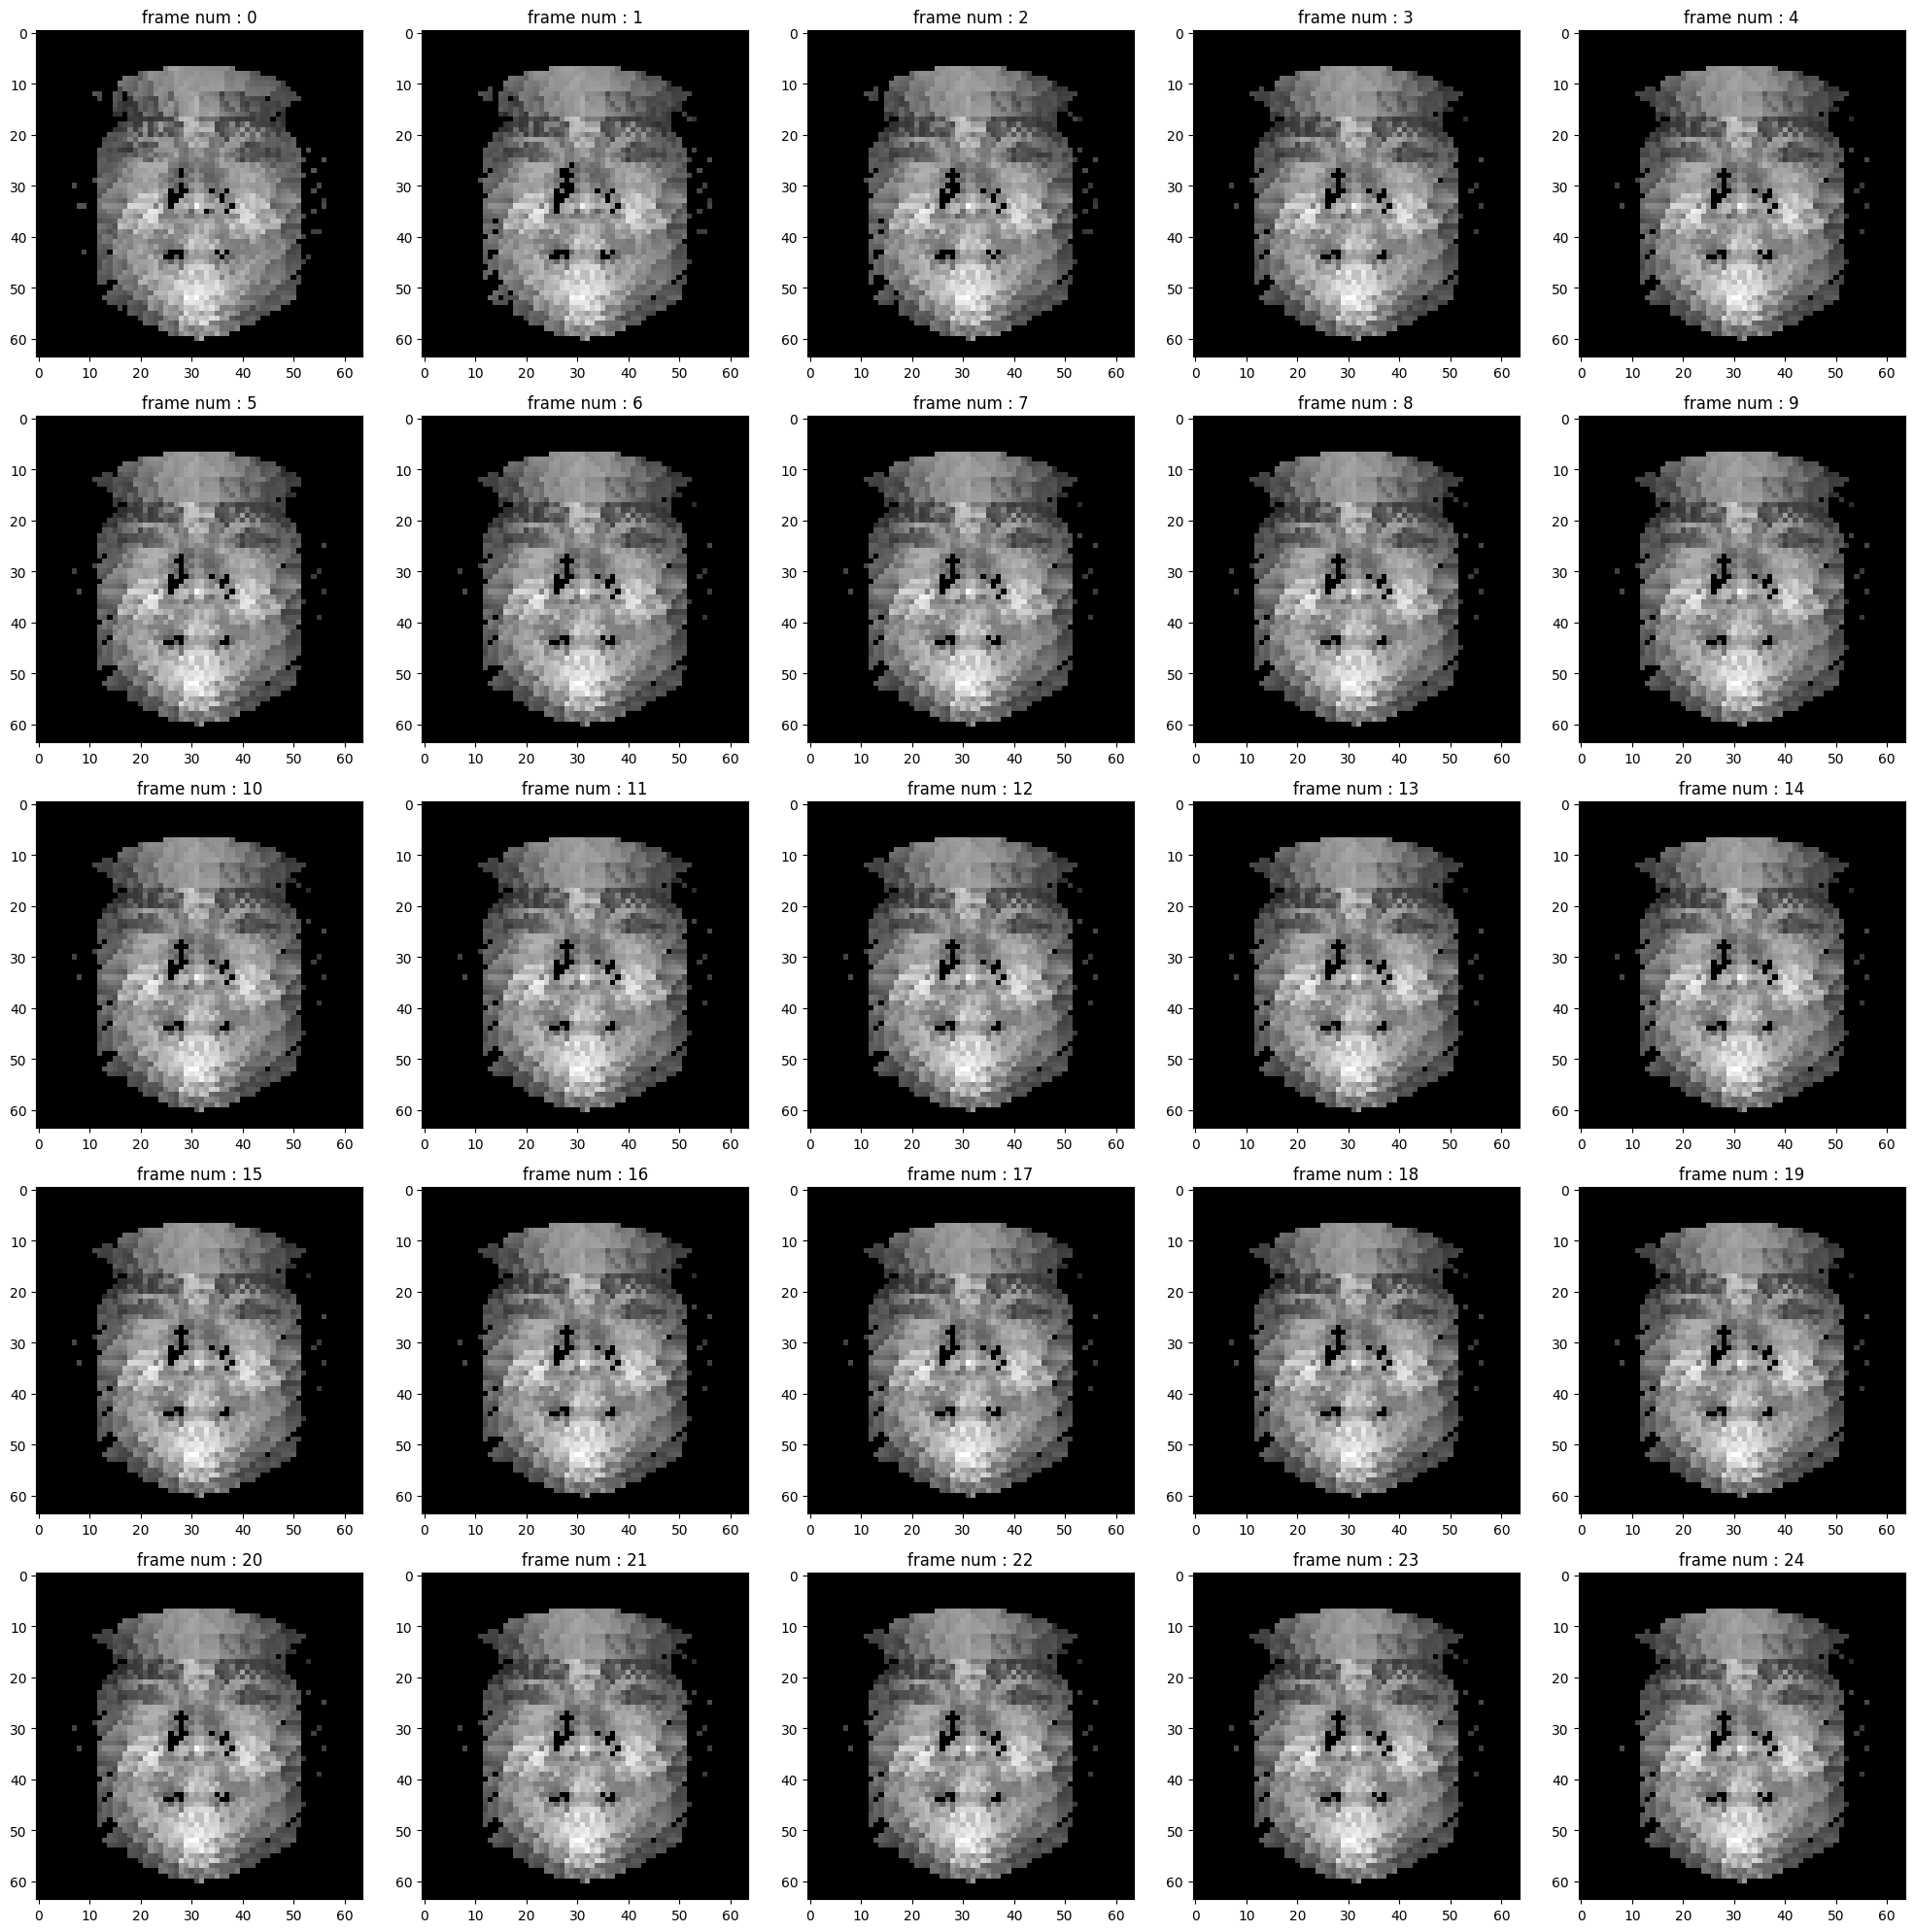

In [5]:
#registration 결과 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_registration_70'
people = sorted(os.listdir(regist_dir))

id = 1
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['nir_uv_data'][:]

print(video.shape)
print(video.dtype)


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()